# 03 - Feature engineering

Features are built from the preprocessing tables (`02_preproc.ipynb`, saved in `data/processed/`) and driven
by the EDA (`01_eda.ipynb`). The code lives in `src/features.py`; this notebook builds the features for train
and test, checks them and gives a first, **train-only** estimate of how useful each group is.

| Group | Idea (from the EDA) |
|---|---|
| `static` | P1 team stats, levels, items, P2 lead stats: weak alone (\|r\| ≤ 0.03), kept for interactions |
| `state` | state after 30 turns: KOs, revealed / vanished Pokémon, total HP, statuses; strongest signal |
| `trend` | total-HP difference along the turns and its slope; curves of wins and losses diverge early |
| `action` | switches, blocked turns, move categories, move groups (sleep, Toxic, setup, ...), expected damage |
| `status_effect` | turns spent asleep / paralysed / poisoned, turns with Substitute, Leech Seed, ... |
| `boost` | boosts of the active Pokémon at turn 30 and highest boost reached, per stat |
| `matchup` | active Pokémon at turn 30: type advantage, effective speed (boosts, paralysis), team type coverage |
| `species_cat` | species names, only for target encoding **inside the CV folds** |

Two points from the EDA shape the design:
- **P2's KOs are under-recorded** (section 5.6): P1 and P2 columns are always kept next to `diff_*`, P2's
  losses are also estimated as `lost_est = KOs + Pokémon vanished with HP ≤ 0.5`, and `robust_columns` gives
  a subset with no feature that depends on P2's recorded KOs (for the "prudent" submission).
- The final evaluation set is private and different from ours: no feature may depend on the test set.

## 0. Setup

In [1]:
import sys
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data import find_data_dir, load_type_chart
from src.features import build_features, robust_columns
from src.validation import SEED, cv_scores, repeated_cv

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
PROC = ROOT / "data" / "processed"

def load(split):
    return [pd.read_pickle(PROC / f"{name}_{split}.pkl") for name in ("team", "timeline", "states")]

species = pd.read_pickle(PROC / "species_table.pkl")   # built from train only
type_chart = load_type_chart(find_data_dir() / "type_chart_gen2.csv")

## 1. Building the features

In [2]:
t0 = time.time()
X_train, groups = build_features(*load("train"), species, type_chart)
X_test, _ = build_features(*load("test"), species, type_chart)
print(f"built in {time.time() - t0:.1f}s | train {X_train.shape} | test {X_test.shape}")

y = X_train.pop("player_won")
CAT = groups["species_cat"]
NUM = [c for c in X_train.columns if c not in CAT]
ROBUST = robust_columns(NUM)
display(pd.Series({g: len(c) for g, c in groups.items()}, name="n_features").to_frame().T)
print(f"numeric: {len(NUM)} | categorical: {len(CAT)} | robust subset: {len(ROBUST)}")
print("dropped from the robust subset:", sorted(set(NUM) - set(ROBUST)))

built in 16.3s | train (10000, 159) | test (5000, 158)


,static,state,trend,action,status_effect,boost,matchup,species_cat
n_features,22,21,12,48,23,20,9,3


numeric: 155 | categorical: 3 | robust subset: 145
dropped from the robust subset: ['diff_ko', 'diff_lost_est', 'p2_first_ko_turn', 'p2_ko', 'p2_ko_by_t20', 'p2_lost_est', 'p2_switch_after_ko', 'p2_vanished', 'p2_vanished_low25', 'p2_vanished_low50']


## 2. Sanity checks

In [3]:
assert list(X_train.columns) == list(X_test.columns), "train and test must have the same columns"
assert X_train.index.is_unique and X_test.index.is_unique

num_train = X_train[NUM]
checks = pd.DataFrame({
    "NaN (train)": num_train.isna().sum(),
    "NaN (test)": X_test[NUM].isna().sum(),
    "inf (train)": np.isinf(num_train).sum(),
    "n_unique (train)": num_train.nunique(),
})
print("constant features:", checks.index[checks["n_unique (train)"] <= 1].tolist())
print("infinite values:", int(checks["inf (train)"].sum()))
display(checks[(checks["NaN (train)"] > 0) | (checks["NaN (test)"] > 0)])

constant features: []
infinite values: 0


,NaN (train),NaN (test),inf (train),n_unique (train)
m_p2_threat,63,25,0,51
m_coverage_diff,63,25,0,318


The only NaNs are in `m_p2_threat` / `m_coverage_diff`, for the few battles where all P1 Pokémon have
fainted (no P1 Pokémon left to threaten). They are imputed inside the model pipeline.

## 3. Univariate signal (train only)

Absolute Pearson correlation with `player_won`. This is only a first look: it ignores interactions and
redundancy, and it is **not** used to select features (selection is done with CV in the next notebook).

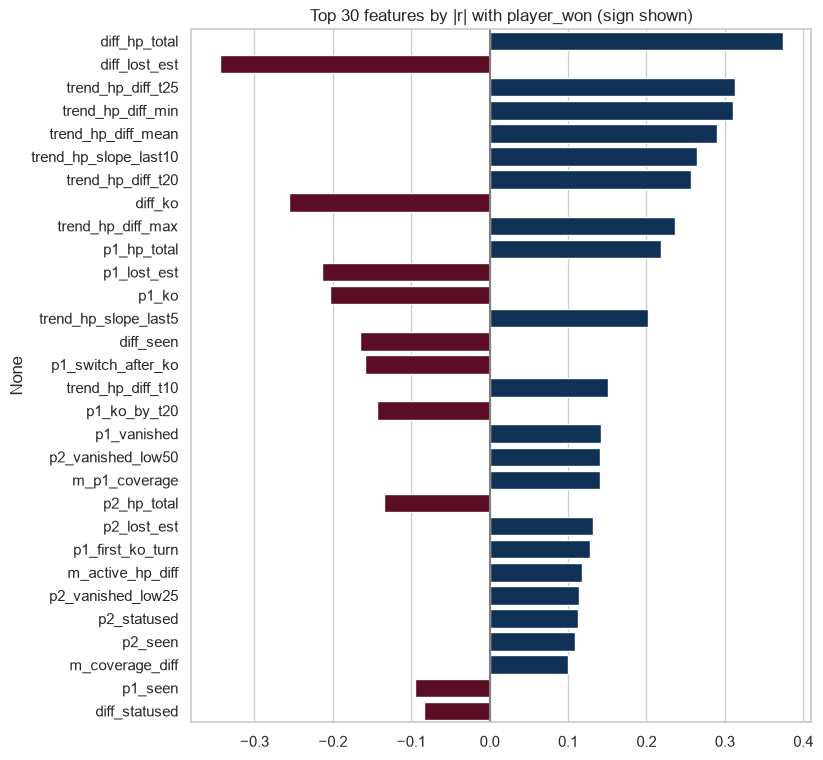

,max,mean,size
state,0.374,0.143,21
trend,0.313,0.192,12
action,0.159,0.032,48
matchup,0.140,0.057,9
boost,0.057,0.023,20
status_effect,0.049,0.025,23
static,0.029,0.011,22


In [4]:
corr = X_train[NUM].corrwith(y)
top = corr.abs().sort_values(ascending=False).head(30)
plt.figure(figsize=(8, 9))
sns.barplot(x=corr[top.index].values, y=top.index, hue=np.sign(corr[top.index].values), palette="RdBu", legend=False)
plt.axvline(0, c="grey"); plt.title("Top 30 features by |r| with player_won (sign shown)"); plt.show()

group_of = {c: g for g, cols in groups.items() for c in cols}
best = corr.abs().groupby(corr.index.map(group_of)).agg(["max", "mean", "size"]).sort_values("max", ascending=False)
best.round(3)

In [5]:
# Highly redundant pairs (|r| > 0.95): fine for boosting, worth knowing for linear models
c = X_train[NUM].corr().abs()
pairs = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack()
print(f"pairs with |r| > 0.95: {(pairs > 0.95).sum()}")
pairs[pairs > 0.95].sort_values(ascending=False).head(15).round(3)

pairs with |r| > 0.95: 3


p1_min_level     p2_lead_level    0.996
p1_n_underlevel  p1_min_level     0.962
                 p2_lead_level    0.954
dtype: float64

## 4. How useful is each group? (5-fold CV on train)

Two reference models, everything fitted inside the folds:
- **Logistic Regression** (median imputation + scaling + L2), sensitive to scale and redundancy;
- **LightGBM** with fixed, untuned parameters.

For each group we measure the group **alone** and **all features minus the group** (ablation).
A single seed is used here; differences below ~0.5 points are noise.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier

logreg = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                       LogisticRegression(C=0.1, max_iter=3000, random_state=SEED))
lgbm = LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=40,
                      subsample=0.8, subsample_freq=1, colsample_bytree=0.7, random_state=SEED,
                      n_jobs=1, verbose=-1)
MODELS = {"logreg": logreg, "lgbm": lgbm}

def evaluate(cols):
    return {name: cv_scores(m, X_train[cols], y).mean() for name, m in MODELS.items()}

t0 = time.time()
rows = {"all numeric": evaluate(NUM), "robust subset": evaluate(ROBUST)}
for g, cols in groups.items():
    if g == "species_cat":
        continue
    rows[f"only {g}"] = evaluate(cols)
    rows[f"all - {g}"] = evaluate([c for c in NUM if c not in cols])
results = pd.DataFrame(rows).T
print(f"done in {time.time() - t0:.0f}s")
results.round(4)

done in 36s


,logreg,lgbm
all numeric,0.6770,0.6781
robust subset,0.6752,0.6797
only static,0.5120,0.5488
all - static,0.6746,0.6767
only state,0.6621,0.6547
all - state,0.6664,0.6728
only trend,0.6526,0.6477
all - trend,0.6788,0.6799
only action,0.5923,0.6001
all - action,0.6720,0.6727


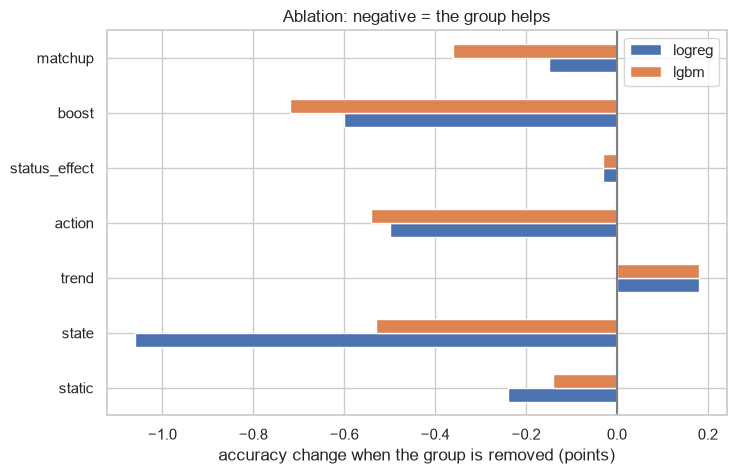

In [7]:
ref = results.loc["all numeric"]
ablation = results[results.index.str.startswith("all - ")].sub(ref)
ablation.index = ablation.index.str.replace("all - ", "")
ax = (ablation * 100).plot.barh(figsize=(8, 5))
ax.axvline(0, c="grey"); ax.set_xlabel("accuracy change when the group is removed (points)")
ax.set_title("Ablation: negative = the group helps"); plt.show()

### 4.1 Repeated CV for the reference configurations

Seeds 42, 7 and 123 (15 scores per configuration).

In [8]:
rep = {}
for cols_name, cols in [("all numeric", NUM), ("robust subset", ROBUST)]:
    for name, m in MODELS.items():
        mean, std = repeated_cv(m, X_train[cols], y)
        rep[(cols_name, name)] = {"mean": mean, "std": std}
pd.DataFrame(rep).T.round(4)

mean     std
all numeric   logreg  0.6746  0.0083
              lgbm    0.6764  0.0080
robust subset logreg  0.6734  0.0078
              lgbm    0.6762  0.0086

## 5. Species target encoding, inside the folds

`TargetEncoder` is placed **inside** the pipeline, so in every fold it is fitted on the training part only
(and it uses an internal cross-fitting on that part). Unknown species get the global mean.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder

def with_target_encoding(model):
    enc = ColumnTransformer([("te", TargetEncoder(target_type="binary", random_state=SEED), CAT)],
                            remainder="passthrough")
    return make_pipeline(enc, model)

te_rows = {}
for name, m in MODELS.items():
    te_rows[name] = {"without species": cv_scores(m, X_train[NUM], y).mean(),
                     "with species TE": cv_scores(with_target_encoding(m), X_train[NUM + CAT], y).mean()}
pd.DataFrame(te_rows).T.assign(delta=lambda d: d["with species TE"] - d["without species"]).round(4)

,without species,with species TE,delta
logreg,0.6770,0.6772,0.0002
lgbm,0.6781,0.6781,0.0000


## 6. Saving the features

In [10]:
X_train.assign(player_won=y).to_pickle(PROC / "features_train.pkl")
X_test.to_pickle(PROC / "features_test.pkl")
with open(PROC / "feature_groups.json", "w") as f:
    json.dump({**groups, "robust": ROBUST}, f, indent=1)
for p in sorted(PROC.glob("feature*")):
    print(f"{p.name:22s} {p.stat().st_size / 1e6:6.1f} MB")

feature_groups.json       0.0 MB
features_test.pkl         6.4 MB
features_train.pkl       12.9 MB


## 7. Summary

**Feature set**: 155 numeric features in 7 groups + 3 species columns; the robust subset keeps 145
(the 10 features based on P2's recorded KOs / vanished Pokémon are dropped). Train and test have the same
columns, no constant or infinite features; the only NaNs (63 train battles, all P1 Pokémon fainted) are imputed
in the pipeline.

**First CV estimate (train only, untuned models)**

| Configuration | LogReg | LightGBM |
|---|---|---|
| all numeric, repeated CV (3 seeds × 5 folds) | 0.6746 ± 0.0083 | 0.6764 ± 0.0080 |
| robust subset, repeated CV | 0.6734 ± 0.0078 | 0.6762 ± 0.0086 |

**What we learned**
- **The battle state drives everything**: `state` alone reaches 0.66 with LogReg, and removing it costs the
  most (-1.1 points LogReg, -0.5 LightGBM).
- **Boosts and actions matter more than their correlations suggest**: removing `boost` costs ~0.6-0.7 points
  and `action` ~0.5, although their univariate |r| is small → they act through interactions.
- **Static information and the turn-30 matchup help a little** (-0.15 to -0.4 points when removed);
  `status_effect` is neutral.
- **`trend` is redundant with `state`**: alone it is strong (0.65), but removing it does not hurt
  (+0.2, within noise). Candidate for removal in feature selection.
- **The robust subset costs nothing** (0.6762 vs 0.6764 with LightGBM): P2's recorded KOs add no information
  once HP and the other features are known. The prudent submission can use it at no cost.
- **Species target encoding (inside the folds) adds nothing** (±0.0002), consistent with the EDA
  (species win rates 0.47-0.57). Not worth its leakage risk.
- Unexpected: `p1_min_level` and `p2_lead_level` are almost identical (r = 0.996) → the 63 battles with
  under-levelled Pokémon are **low-level battles on both sides**, probably a different format. Kept and flagged.
- Ceiling: all configurations sit around **0.675-0.68**; differences between them are mostly within the noise
  (std ≈ 0.8 points). The outcome after 30 turns of a 30-80 turn battle is intrinsically uncertain.

**Next steps** (`04_models.ipynb`): feature selection (permutation importance, top-K curve, drop `trend`?),
tuning in CV, more models (CatBoost, SVM, ensembles), the robustness stress test on P2's KOs.